In [1]:
import xarray as xr
import matplotlib.pyplot as plt

In [2]:
ds_smls = xr.open_dataset('/Users/chwala-c/data/OpenSat4Weather_data/sml_data_2022.nc')
ds_radar_along_smls = xr.open_dataset('/Users/chwala-c/data/OpenSat4Weather_data/radar_along_sml_data_2022.nc')

ds_smls

<xarray.Dataset> Size: 760MB
Dimensions:              (sml_id: 215, time: 220320)
Coordinates:
  * sml_id               (sml_id) <U9 8kB 'FRA-00002' ... 'FRA-00737'
  * time                 (time) datetime64[ns] 2MB 2022-08-01 ... 2022-12-31T...
    site_0_lat           (sml_id) float64 2kB ...
    site_0_lon           (sml_id) float64 2kB ...
    site_0_alt           (sml_id) int64 2kB ...
    satellite_azimuth    (sml_id) float64 2kB ...
    satellite_elevation  (sml_id) float64 2kB ...
    satellite            (sml_id) <U11 9kB ...
    hardware             (sml_id) <U4 3kB ...
Data variables:
    rsl                  (sml_id, time) float64 379MB ...
    deg0l                (sml_id, time) float64 379MB ...
Attributes:
    creation_date:  2025-07-28
    title:          Satellite Microwave Link dataset Aug-Dec 2022
    version:        1.0
    convention:     OpenSense-1.0
    reference:      rsl data from HDrain, deg0l data from ERA5 (https://clima...
    authors:        Roberto Nebuloni, Maximilian Graf, Greta Cazzaniga, Franc...

Text(0.5, 0, 'time')

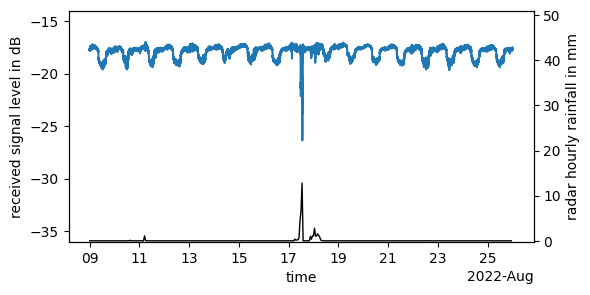

In [3]:

sml_id = 'FRA-00022'

fig, ax = plt.subplots(figsize=(6, 3))
ds_smls.rsl.sel(sml_id=sml_id).sel(time=slice('2022-08-09', '2022-08-25')).plot()
ax.set_ylim(-36, -14)
ax.set_ylabel("received signal level in dB")

ax2 = ax.twinx()
ds_radar_along_smls.rainfall_amount.sel(sml_id=sml_id).resample(time='1h').sum().sel(time=slice('2022-08-09', '2022-08-25')).plot(
    ax=ax2, color='k', zorder=-1, linewidth=1,
)
ax2.set_ylim(-0.2, 51)
ax2.set_ylabel("radar hourly rainfall in mm")
ax.set_title('')
ax2.set_title('')
ax.set_xlabel("time")


In [4]:
# WIP...